# Exercise 1: From municipalities to counties

Each Norwegian municipality (*kommune*) belongs to a county (*fylke*). In this
exercise, you will use municipality-level data from Statistics Norway (SSB) to
compare counties by their number of municipalities, population, and population
density.

1.  Load `municipalities.csv` from the `data/ssb/` folder. Keep only the columns
    `municipality`, `county`, `population`, and `land_area`, and display the first
    five rows.

    Each row represents one municipality. The column `population` records its
    number of residents, and `land_area` records its land area in km².

2.  Group the data by `county` and count the municipalities in each county.
    Display the counts in descending order. Which county contains the most
    municipalities?

    *Hint:* Applying `size()` to a grouped DataFrame counts the rows in each group.
    Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the counts.

3.  Create a DataFrame named `df_counties` containing the total population and
    total land area of each county. Report the three counties with the largest
    populations.

    Check that summing the county populations gives the same national total as
    summing the municipality populations.

4.  Add a column named `density` to `df_counties`, containing each county's
    population density in residents per km² of land:

    $$
    \text{Population density} =
    \frac{\text{Total population}}{\text{Total land area}}
    $$

    Report the three counties with the highest population densities. Does the
    county with the largest population also have the highest population density?

## Solution

#### Part 1 — Loading the data

In [1]:
import pandas as pd

# Use files in the local data/ directory
DATA_PATH = '../../data'

# Uncomment this to load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH2-H26/main/data'

In [2]:
# Columns needed for the county comparisons
cols = ['municipality', 'county', 'population', 'land_area']

# Path to the municipalities CSV file
file = f'{DATA_PATH}/ssb/municipalities.csv'

# Read the municipalities CSV file into a DataFrame
df_municipalities = pd.read_csv(file, usecols=cols)

# Display the first five municipalities
df_municipalities.head()

,municipality,county,population,land_area
0,Oslo,Oslo,724290,426
1,Bergen,Vestland,293709,445
2,Trondheim - Tråante,Trøndelag - Trööndelage,216518,496
3,Stavanger,Rogaland,150123,256
4,Bærum,Akershus,132358,189


#### Part 2 — Counting municipalities

In [3]:
# Group municipalities by county
groups = df_municipalities.groupby('county')

# Each row is a municipality, so group sizes give municipality counts
counts = groups.size()

# Display municipality counts from largest to smallest
counts.sort_values(ascending=False)

county
Innlandet                           46
Vestland                            43
Nordland - Nordlánnda               41
Trøndelag - Trööndelage             38
Møre og Romsdal                     27
Agder                               25
Rogaland                            23
Akershus                            21
Troms - Romsa - Tromssa             21
Finnmark - Finnmárku - Finmarkku    18
Buskerud                            18
Telemark                            17
Østfold                             12
Vestfold                             6
Oslo                                 1
dtype: int64

Innlandet has the most municipalities, with 46.

#### Part 3 — County totals

In [4]:
# Aggregate both columns to obtain one row per county
df_counties = groups[['population', 'land_area']].sum()

# Display the three most populous counties
df_counties.sort_values('population', ascending=False).head(3)

,population,land_area
county,,
Akershus,740680,5471
Oslo,724290,426
Vestland,655210,31964


In [5]:
# Aggregation should preserve the national population total
municipality_total = df_municipalities['population'].sum()
county_total = df_counties['population'].sum()

print(f'Total from municipalities: {municipality_total:,d}')
print(f'Total from counties:       {county_total:,d}')
print('Totals match:', municipality_total == county_total)

Total from municipalities: 5,594,340
Total from counties:       5,594,340
Totals match: True


#### Part 4 — Population density

In [6]:
# Divide county totals to obtain residents per square kilometer of land
df_counties['density'] = df_counties['population'] / df_counties['land_area']

# Display the three most densely populated counties
df_counties.sort_values('density', ascending=False).head(3).round(1)

,population,land_area,density
county,,,
Oslo,724290,426,1700.2
Akershus,740680,5471,135.4
Vestfold,258071,2092,123.4


Oslo has the highest population density, whereas Akershus has the largest
population. Vestfold is third in population density.

We calculate county density by dividing total population by total land area.
Taking a simple average of municipality densities would give each municipality
equal weight, regardless of its land area.

<span style="display: none;">SolutionEnd</span>

***
# Exercise 2: House price levels and dispersion

For this exercise, we're using around 3,000 observations of house prices and house
characteristics from Ames, a small city in Iowa.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    To familiarize yourself with the data, report the columns present in the DataFrame and 
    then restrict the data to the columns `SalePrice` (price in thousands of US dollars) 
    and `Neighborhood` (abbreviated name of the neighborhood).
    
    Count the number of observations in each neighborhood. Drop all observations
    belonging to neighborhoods with fewer than 20 observations. Use this
    restricted data set for the remainder of the exercise.

    Check that there are no observations with missing values in the final data set.

2.  Compute the average house price (column `SalePrice`) by neighborhood (column
    `Neighborhood`). List the three neighborhoods with the highest average prices,
    for example by using
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html).

    Create a bar chart showing the average sale price for all remaining
    neighborhoods in descending order.

    *Hint:* You can create the bar chart by either using pandas's 
    [`DataFrame.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html)
    or Matplotlib's
    [`bar()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html).

3.  You want to quantify the price dispersion in each neighborhood. To this end, compute the standard deviation of the sale price by neighborhood using 
    [`std()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html).
    Which are the three neighborhoods with the most dispersed prices?

4.  Create a scatter plot with the average house price on the $x$-axis and the standard deviation on the $y$-axis.
    Is there a relationship between the average house prices and their dispersion within a neighborhood?

    *Hint:* You can create the scatter plot by either using pandas's 
    [`DataFrame.plot.scatter()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html)
    or Matplotlib's 
    [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html).

5.  **[Advanced]** To compare neighborhoods with different average prices,
    express the standard deviation as a percentage of the average price:

    $$
    \text{Relative price spread (\%)} =
    100 \times \frac{\text{standard deviation}}{\text{average price}}
    $$

    This is the
    [coefficient of variation](
    https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/coefvari.htm
    )
    expressed as a percentage. For example, a standard deviation of 20 thousand
    USD and an average price of 100 thousand USD give a relative spread of 20%.

    Calculate the relative price spread for each neighborhood. Create a scatter
    plot with the average house price on the $x$-axis and the relative price spread
    on the $y$-axis. Do neighborhoods with higher average prices also have more
    dispersed prices relative to their average? Compare the pattern with Part 4.

## Solution

#### Part 1 — Loading the data

After loading the data and keeping the two requested columns, we count the
observations in each neighborhood. As in Lecture 4,
[`transform()`](
https://pandas.pydata.org/docs/reference/api/pandas.api.typing.SeriesGroupBy.transform.html
)
assigns a group result to every row. Here, `transform('size')` gives each house the
number of observations in its neighborhood. We then use boolean indexing to keep
only rows whose neighborhood has at least 20 observations. Applying this restriction
to `df` ensures that all subsequent calculations use the same sample.

In [7]:
# Use files in the local data/ directory
DATA_PATH = '../../data'

# Uncomment this to load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH2-H26/main/data'

In [8]:
import pandas as pd

# Path to Ames housing CSV file
file = f'{DATA_PATH}/ames_houses.csv'

# Read in file
df = pd.read_csv(file)

# Report columns present in the DataFrame
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   LotArea           2930 non-null   float64
 1   Neighborhood      2930 non-null   str    
 2   OverallQuality    2930 non-null   int64  
 3   OverallCondition  2930 non-null   int64  
 4   YearBuilt         2930 non-null   int64  
 5   YearRemodeled     2930 non-null   int64  
 6   BuildingType      2930 non-null   str    
 7   CentralAir        2930 non-null   str    
 8   LivingArea        2930 non-null   float64
 9   Bathrooms         2930 non-null   int64  
 10  Bedrooms          2930 non-null   int64  
 11  Fireplaces        2930 non-null   int64  
 12  SalePrice         2930 non-null   float64
 13  YearSold          2930 non-null   int64  
 14  MonthSold         2930 non-null   int64  
 15  HasGarage         2930 non-null   int64  
dtypes: float64(3), int64(10), str(3)
memory usage: 366.4 

In [9]:
# Keep only the columns SalePrice and Neighborhood
df = df[['SalePrice', 'Neighborhood']]

# Assign each house the number of observations in its neighborhood
counts = df.groupby('Neighborhood')['SalePrice'].transform('size')

# Keep houses in neighborhoods with at least 20 observations
df = df.loc[counts >= 20].copy()
print('Remaining neighborhoods:', len(df['Neighborhood'].value_counts()))
print(f'Remaining observations: {len(df):,d}')

Remaining neighborhoods: 24
Remaining observations: 2,909


To check whether there are any missing values, we can for example use 
[`info()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)
with `show_counts=True`:

In [10]:
N = len(df)
print(f'Total number of observations: {N:,d}\n')

# Print number of non-missing observations
df.info(show_counts=True)

Total number of observations: 2,909

<class 'pandas.DataFrame'>
Index: 2909 entries, 0 to 2929
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SalePrice     2909 non-null   float64
 1   Neighborhood  2909 non-null   str    
dtypes: float64(1), str(1)
memory usage: 68.2 KB


Since the number of non-missing observations is the same as the total number of observations, there are no missing values in the data.

#### Part 2 — Average sale price by neighborhood

In [11]:
# Group data by neighborhood
groups = df.groupby('Neighborhood')

# Compute mean house price by neighborhood
mean_price = groups['SalePrice'].mean()

# Print first 10 entries, rounded to 1 decimal place
mean_price.head(10).round(1)

Neighborhood
Blmngtn    196.7
BrDale     105.6
BrkSide    124.8
ClearCr    208.7
CollgCr    201.8
Crawfor    207.6
Edwards    130.8
Gilbert    190.6
IDOTRR     103.8
MeadowV     95.8
Name: SalePrice, dtype: float64

These means are not sorted by average price, so we use `sort_values()` to sort them.

In [12]:
# Sort in descending order, with highest values on top
mean_price = mean_price.sort_values(ascending=False)

# Print the 3 neighborhoods with the highest average price, rounded to 1 decimal place
mean_price.head(3).round(1)

Neighborhood
NoRidge    330.3
StoneBr    324.2
NridgHt    322.0
Name: SalePrice, dtype: float64

If we are not interested in any of the intermediate objects, we can chain all these
operations into a single expression as follows:

In [13]:
# Print the 3 neighborhoods with the highest average price
top3 = (
    df.groupby('Neighborhood')['SalePrice']
    .mean()
    .sort_values(ascending=False)
    .head(3)
    .round(1)
)
top3

Neighborhood
NoRidge    330.3
StoneBr    324.2
NridgHt    322.0
Name: SalePrice, dtype: float64

Finally, we can use the pandas plotting functionality to create a bar chart of average house prices:

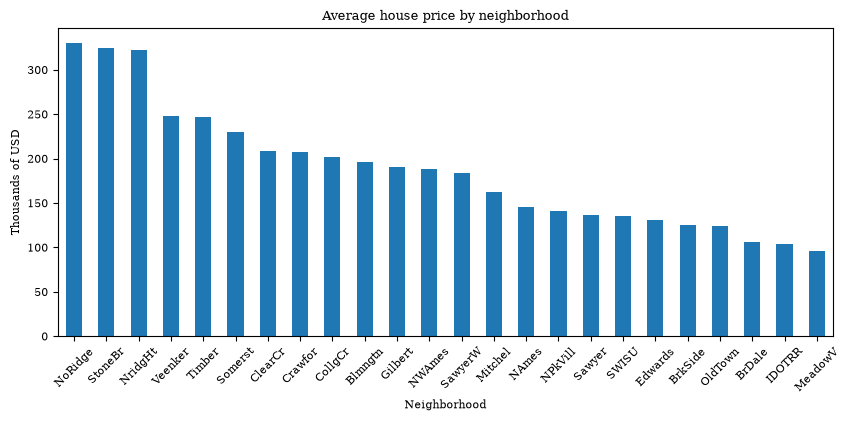

In [14]:
# Create bar chart. Suppress the output of the plot command by assigning it to a variable.
_ = mean_price.plot.bar(
    title='Average house price by neighborhood',
    ylabel='Thousands of USD',
    figsize=(10, 4),
    rot=45,
)

Alternatively, this can be achieved using the Matplotlib API as follows:

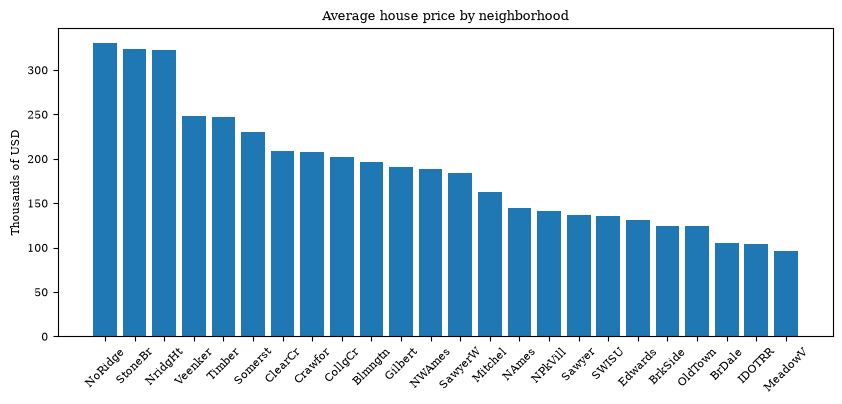

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.bar(mean_price.index, mean_price)
# Rotate x-axis labels by 45 degrees to avoid overlap
plt.tick_params(axis='x', rotation=45)
plt.ylabel('Thousands of USD')
_ = plt.title('Average house price by neighborhood')

#### Part 3 — House price dispersion within neighborhoods

Computing the standard deviation and sorting in descending order is performed in exactly the same way as for the mean:

In [16]:
# Compute standard deviations by neighborhood and sort in descending order
std_price = df.groupby('Neighborhood')['SalePrice'].std().sort_values(ascending=False)

# Print the 3 neighborhoods with the most dispersed prices
std_price.head(3).round(1)

Neighborhood
StoneBr    119.3
NoRidge    101.4
NridgHt     95.9
Name: SalePrice, dtype: float64

#### Part 4 — Price level vs dispersion

Next, we create a scatter plot which visualizes the relationship between average house prices and the dispersion within each neighborhood.

If we want to use the pandas plotting functions, we first need to combine the mean
and standard deviation into a single DataFrame.
We could do this using the 
[`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
function, but instead we'll choose
to recompute the mean and standard deviation in a single call to 
[`agg()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html):

In [17]:
# Compute statistics of interest (mean, std) in a single call to agg()
df_stats = df.groupby('Neighborhood')['SalePrice'].agg(['mean', 'std'])

We can then use the pandas 
[`scatter()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html)
method to create the scatter plot:

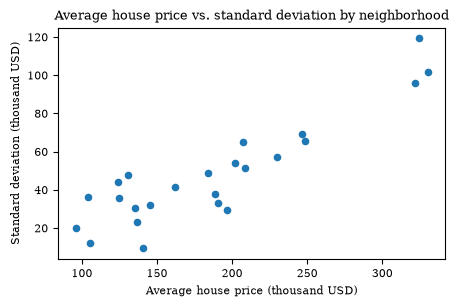

In [18]:
_ = df_stats.plot.scatter(
    x='mean',
    y='std',
    title='Average house price vs. standard deviation by neighborhood',
    xlabel='Average house price (thousand USD)',
    ylabel='Standard deviation (thousand USD)',
    figsize=(5, 3),
)

Alternatively, we can create the scatter plot using Matplotlib's own
[`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html):

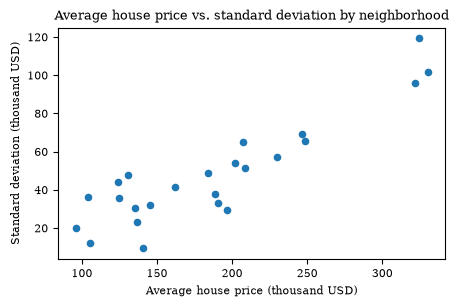

In [19]:
# Create scatter plot using Matplotlib functions
plt.figure(figsize=(5, 3))
plt.scatter(df_stats['mean'], df_stats['std'], s=20)
plt.title('Average house price vs. standard deviation by neighborhood')
plt.xlabel('Average house price (thousand USD)')
_ = plt.ylabel('Standard deviation (thousand USD)')

As the scatter plot shows, there is a positive relationship between the average
house price and the dispersion of prices as measured by the standard deviation.
Neighborhoods with higher average prices tend to have greater dispersion in dollar
terms. This does not establish that prices are more dispersed relative to the
neighborhood mean.

#### Part 5 — Relative price spread [Advanced]

We express each neighborhood's standard deviation as a percentage of its average
price. If every price doubled, both the average and the standard deviation would
double, leaving this percentage unchanged.

In [20]:
# Express the standard deviation as a percentage of the average price
df_stats['relative_spread'] = 100 * df_stats['std'] / df_stats['mean']

We can now plot the average house price against the relative price spread.

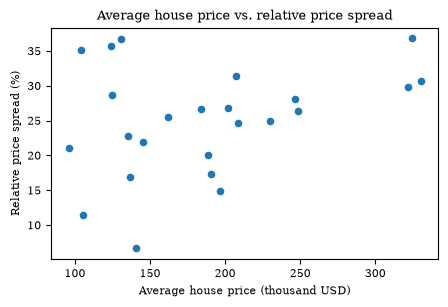

In [21]:
_ = df_stats.plot.scatter(
    x='mean',
    y='relative_spread',
    title='Average house price vs. relative price spread',
    xlabel='Average house price (thousand USD)',
    ylabel='Relative price spread (%)',
    figsize=(5, 3),
)

The positive relationship is much less clear than in Part 4. Neighborhoods with
higher average prices do not consistently have more dispersed prices relative to
their average.

For example, StoneBr and Edwards have very different average prices and standard
deviations in dollar terms, but almost identical relative price spreads:

| Neighborhood | Average price | Standard deviation | Relative price spread |
|---|---:|---:|---:|
| StoneBr | 324.2 | 119.3 | 36.8% |
| Edwards | 130.8 | 48.0 | 36.7% |

Average prices and standard deviations in the table are in thousands of USD.

<span style="display: none;">SolutionEnd</span>

***
# Exercise 3: Determinants of house prices

For this exercise, we're using around 3,000 observations of house prices and house
characteristics from Ames, a small city in Iowa, to understand how house prices vary
with selected house characteristics.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    Keep only the columns `SalePrice` (price in thousands of US dollars), `LotArea` (lot area in m²), `YearBuilt`, and `Bedrooms` (number of bedrooms).

    Restrict your data set to houses with one or more bedrooms and a lot area of at least 100 m².
    Report the sample size after applying these restrictions.

2.  Compute the average year in which a house was built (using the column `YearBuilt`). 

    Classify houses as _"newer"_ if they were built after the sample's average
    construction year, and _"older"_ otherwise. Store this classification in a new
    column `Newer`, with 1 for newer houses and 0 for older houses.

    What is the average year of construction within these two categories?

3.  Create a new column `Rooms` which categorizes the number of `Bedrooms` into
    three groups: 1–2, 3, and 4 or more. Use the values 2, 3, and 4 to represent
    these groups. You can create these categories using boolean indexing,
    [`np.where()`](https://numpy.org/doc/2.0/reference/generated/numpy.where.html),
    pandas's
    [`where()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.where.html),
    [`map()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html),
    [`clip()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html),
    or some other way.

4.  Compute the mean sale price and number of observations within each group
    formed by `Newer` and `Rooms` (for a total of 6 different categories).

    By how much does the average price of newer houses with 4+ bedrooms exceed that
    of older houses with 1–2 bedrooms?

5.  Create a figure with two subplots arranged in two columns. The left column
    should contain a bar chart showing the average house price by the number of
    bedrooms (1–2, 3, 4+) for _older_ houses, whereas the right column should show the
    corresponding bars for _newer_ houses. Use a shared vertical scale so that prices
    can be compared across the two panels.

## Solution

#### Part 1 — Loading the data

In [22]:
# Use files in the local data/ directory
DATA_PATH = '../../data'

# Uncomment this to load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH2-H26/main/data'

In [23]:
import pandas as pd

# Path to Ames housing CSV file
file = f'{DATA_PATH}/ames_houses.csv'

# Read in file
df = pd.read_csv(file)

In [24]:
# Restrict DataFrame to columns used in this exercise
df = df[['SalePrice', 'LotArea', 'YearBuilt', 'Bedrooms']]

In [25]:
# Drop observations with zero bedrooms and small lot areas
df = df.query('Bedrooms > 0 & LotArea >= 100').copy()

In [26]:
# Total number of observations in the final sample
print(f'Number of observations in final sample: {len(df):,d}')

Number of observations in final sample: 2,922


#### Part 2 — Indicator for older/newer houses

We first compute the average year in which the houses in the sample were built,
which we'll use below to categorize houses as _"older"_ or _"newer"_.

In [27]:
# Compute the average year in which houses were built
mean_year = df['YearBuilt'].mean()
print(f'Average year of construction: {mean_year:.1f}')

Average year of construction: 1971.3


We create the `Newer` indicator from a logical comparison. The comparison returns
`True` for newer houses and `False` for older houses. We then use `astype(int)` to
convert these values to 1 and 0, as requested.

In [28]:
# Create indicator for whether a house was built after the average year
df['Newer'] = (df['YearBuilt'] > mean_year).astype(int)

# Tabulate the average year of construction for newer/older houses
df.groupby('Newer')['YearBuilt'].mean().round(1)

Newer
0    1945.1
1    1995.7
Name: YearBuilt, dtype: float64

As you can see, among the _"older"_ houses, the average year of construction was
1945, whereas _"newer"_ houses were built around 1996 on average.

#### Part 3 — Number of bedrooms

There are several ways to recode the `Bedrooms` column into the categories 1–2, 3,
and 4 or more. We use the values 2, 3, and 4 to represent these groups. The code
below shows several common approaches:

In [29]:
# Alternative using boolean indexing
df['Rooms'] = df['Bedrooms']

# Group houses with one or two bedrooms together
df.loc[df['Bedrooms'] <= 2, 'Rooms'] = 2

# Group houses with four or more bedrooms together
df.loc[df['Bedrooms'] >= 4, 'Rooms'] = 4

In [30]:
# Alternative using Series.where()
df['Rooms'] = df['Bedrooms'].where(df['Bedrooms'] > 2, 2)
df['Rooms'] = df['Rooms'].where(df['Rooms'] < 4, 4)

In [31]:
import numpy as np

# Alternative using np.where()
df['Rooms'] = np.where(df['Bedrooms'] <= 2, 2, df['Bedrooms'])
df['Rooms'] = np.where(df['Rooms'] >= 4, 4, df['Rooms'])

In [32]:
# Alternative using np.fmax() and np.fmin()
df['Rooms'] = np.fmax(df['Bedrooms'], 2)
df['Rooms'] = np.fmin(df['Rooms'], 4)

# Alternative using Series.map() with a lambda
df['Rooms'] = df['Bedrooms'].map(lambda n: min(max(n, 2), 4))

# Alternative using Series.clip()
df['Rooms'] = df['Bedrooms'].clip(lower=2, upper=4)

We can use 
[`pd.crosstab()`](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html)
to verify that the mapping of bedrooms worked as intended:

In [33]:
# Cross-tabulate the new column Rooms vs. Bedrooms
pd.crosstab(df['Bedrooms'], df['Rooms'])

Rooms,2,3,4
Bedrooms,,,
1,112,0,0
2,743,0,0
3,0,1597,0
4,0,0,400
5,0,0,48
6,0,0,21
8,0,0,1


This table shows that houses with one or two bedrooms are mapped to category 2,
those with three bedrooms to category 3, and those with four or more bedrooms to
category 4, as intended.

#### Part 4 — House prices by category

In [34]:
# Compute mean house prices and observation counts within each category
df_price_stats = df.groupby(['Newer', 'Rooms'])['SalePrice'].agg(['mean', 'count'])

# Retain the mean prices for the comparison and plots below
mean_prices = df_price_stats['mean']
df_price_stats.round(1)

mean  count
Newer Rooms              
0     2      116.0    427
      3      141.3    727
      4      161.4    254
1     2      213.6    428
      3      211.8    870
      4      273.2    216

In [35]:
# Mean price of newer houses with 4+ bedrooms minus older houses with 1–2 bedrooms
diff = mean_prices.loc[1, 4] - mean_prices.loc[0, 2]

print(
    'Mean price difference (newer 4+ bedrooms minus older 1–2 bedrooms): '
    f'{diff:,.1f} thousand USD'
)

Mean price difference (newer 4+ bedrooms minus older 1–2 bedrooms): 157.1 thousand USD


The group means are based on between 216 and 870 houses. The counts show how much
data supports each mean; smaller groups can be more sensitive to unusually priced
sales.

Newer houses with 4+ bedrooms sell for approximately 157.1 thousand USD more on
average than older houses with 1–2 bedrooms. This comparison changes both the
construction-year category and the bedroom count. The groups may also differ in
neighborhood, living area, and quality, so the price gap does not isolate the
separate effect of either characteristic. The calculation uses the unrounded
group means.

#### Part 5 — Plot house prices by category

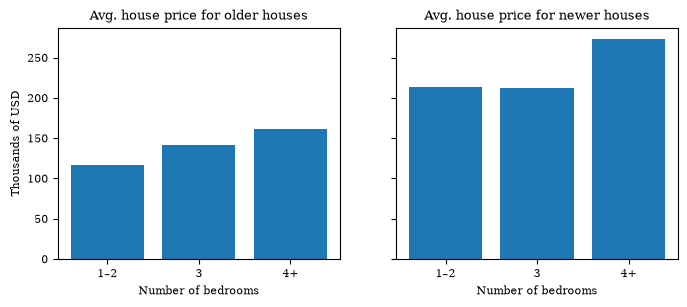

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)

# Label the bedroom categories represented by Rooms values 2, 3, and 4
xvalues = ['1–2', '3', '4+']

# Create bar charts for older houses
axes[0].bar(xvalues, mean_prices.loc[0])
axes[0].set_title('Avg. house price for older houses')
axes[0].set_ylabel('Thousands of USD')
axes[0].set_xlabel('Number of bedrooms')

# Create bar charts for newer houses
axes[1].bar(xvalues, mean_prices.loc[1])
axes[1].set_title('Avg. house price for newer houses')
_ = axes[1].set_xlabel('Number of bedrooms')

<span style="display: none;">SolutionEnd</span>

***
# Exercise 4: Inflation and unemployment in the US

In this exercise, you'll be working with monthly observations of selected
macroeconomic variables for the United States obtained from
[FRED](https://fred.stlouisfed.org/).
The data set starts in 1948 and contains observations for a total of 936 months.

1.  Load the data from the file `FRED_monthly.csv` located in the `data/FRED`
    folder. Parse `DATE` as dates and use it as the DataFrame index. Sort the
    observations in chronological order, then print the first 10 observations to
    get an idea of what the data looks like.

    Keep only the columns `Year`, `Month`, `CPI`, and `UNRATE`, retaining the date
    index. Perform this analysis only on observations prior to 1970 and drop the
    rest, leaving the sample period 1948–1969.

2.  The column `CPI` stores the consumer price index (CPI) for the US.
    Create a new column `Inflation` which contains _year-over-year inflation in
    percent_: the percent change in the CPI relative to the same month in the
    previous year. Apply
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
    to the column `CPI`.

    *Hints:*

    -   Since this is monthly data, pass `periods=12` to `pct_change()` to get
        year-over-year changes.
    -   Multiply the values returned by `pct_change()` by 100 to get percent
        values.

3.  Compute the average unemployment rate (column `UNRATE`) over the restricted
    1948–1969 sample. Create a new column `UNRATE_HIGH` that contains an indicator
    whenever the unemployment rate is above its average value
    (_"high unemployment period"_).

    -   How many observations fall into the high- and low-unemployment periods?
    -   What is the average unemployment rate in the high- and low-unemployment periods?

4.  Compute the average year-over-year inflation rate for high- and
    low-unemployment periods using the available observations. Is there any
    difference?

    Visualize this relationship by creating a scatter plot with the unemployment rate on the $x$-axis and inflation on the $y$-axis, and assign different colors 
    to observations from the low- and high-unemployment periods.

5.  Use 
    [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
    to compute the calendar-year average of the monthly year-over-year inflation
    rates.

    -   Report the three years with the highest averages.
    -   Create a plot that shows these calendar-year averages over the sample period.

    *Hint:* Use the resampling rule `'YE'` when calling `resample()`.

## Solution

#### Part 1 — Loading the data

In [37]:
# Use files in the local data/ directory
DATA_PATH = '../../data'

# Uncomment this to load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH2-H26/main/data'

In [38]:
import pandas as pd

# Path to monthly FRED data
file = f'{DATA_PATH}/FRED/FRED_monthly.csv'

# Read in file using dates as the index
df = pd.read_csv(file, parse_dates=['DATE'], index_col='DATE')

# Arrange observations in chronological order
df = df.sort_index()

# Print columns present in the DataFrame
df.info(show_counts=True)

<class 'pandas.DataFrame'>
DatetimeIndex: 936 entries, 1948-01-01 to 2025-12-01
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Year      936 non-null    int64  
 1   Month     936 non-null    int64  
 2   CPI       935 non-null    float64
 3   UNRATE    935 non-null    float64
 4   FEDFUNDS  858 non-null    float64
 5   REALRATE  528 non-null    float64
 6   LFPART    935 non-null    float64
dtypes: float64(5), int64(2)
memory usage: 58.5 KB


In [39]:
# Print first 10 observations
df.head(10)

,Year,Month,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
DATE,,,,,,,
1948-01-01,1948,1,23.7,3.4,NaN,NaN,58.6
1948-02-01,1948,2,23.7,3.8,NaN,NaN,58.9
1948-03-01,1948,3,23.5,4.0,NaN,NaN,58.5
1948-04-01,1948,4,23.8,3.9,NaN,NaN,59.0
1948-05-01,1948,5,24.0,3.5,NaN,NaN,58.3
1948-06-01,1948,6,24.2,3.6,NaN,NaN,59.2
1948-07-01,1948,7,24.4,3.6,NaN,NaN,59.3
1948-08-01,1948,8,24.4,3.9,NaN,NaN,58.9
1948-09-01,1948,9,24.4,3.8,NaN,NaN,58.9


In [40]:
# Keep only columns of interest for this analysis
df = df[['Year', 'Month', 'CPI', 'UNRATE']]

# Keep only periods before 1970
df = df.query('Year < 1970')

# Print size of the final data set
print(f'Number of observations in final sample: {len(df):,d}')

Number of observations in final sample: 264


#### Part 2 — Compute year-over-year inflation

In [41]:
# Compute year-over-year inflation as the 12-month percent change of the CPI
df['Inflation'] = df['CPI'].pct_change(periods=12) * 100

# Print first 15 observations
df.head(15)

,Year,Month,CPI,UNRATE,Inflation
DATE,,,,,
1948-01-01,1948,1,23.7,3.4,NaN
1948-02-01,1948,2,23.7,3.8,NaN
1948-03-01,1948,3,23.5,4.0,NaN
1948-04-01,1948,4,23.8,3.9,NaN
1948-05-01,1948,5,24.0,3.5,NaN
1948-06-01,1948,6,24.2,3.6,NaN
1948-07-01,1948,7,24.4,3.6,NaN
1948-08-01,1948,8,24.4,3.9,NaN
1948-09-01,1948,9,24.4,3.8,NaN


The first 12 observations of `Inflation`, covering 1948, are missing because the
data do not contain the corresponding CPI observations for 1947. We therefore
cannot compute year-over-year inflation for 1948.

#### Part 3 — Unemployment rates

In [42]:
# Compute average unemployment over the restricted 1948–1969 sample
unrate_avg = df['UNRATE'].mean()
print(f'Average unemployment rate: {unrate_avg:.1f}%')

Average unemployment rate: 4.7%


In [43]:
# Create indicator for above-average unemployment rate
df['UNRATE_HIGH'] = df['UNRATE'] > unrate_avg

# Tabulate number of periods with above and below-average unemployment
df['UNRATE_HIGH'].value_counts()

UNRATE_HIGH
False    141
True     123
Name: count, dtype: int64

In [44]:
# Tabulate average unemployment rate in high- and low-unemployment periods
df.groupby('UNRATE_HIGH')['UNRATE'].mean()

UNRATE_HIGH
False    3.697872
True     5.781301
Name: UNRATE, dtype: float64

#### Part 4 — Inflation in low/high unemployment periods

In [45]:
# Compute average year-over-year inflation in high- and low-unemployment periods
df.groupby('UNRATE_HIGH')['Inflation'].mean()

UNRATE_HIGH
False    3.110456
True     0.942056
Name: Inflation, dtype: float64

Average year-over-year inflation is approximately 3.11% in low-unemployment months
and 0.94% in high-unemployment months, a difference of 2.17 percentage points.
Higher unemployment is associated with lower average inflation within this sample
period.

Next, we visualize this relationship using a scatter plot that assigns different
colors to periods with low- and high-unemployment rates.

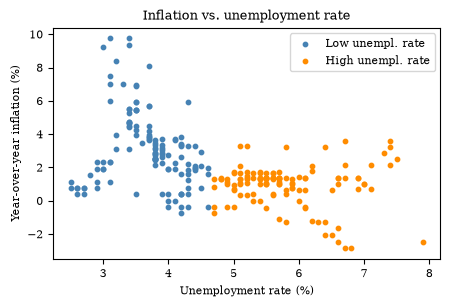

In [46]:
import matplotlib.pyplot as plt

df_hi = df.loc[df['UNRATE_HIGH']]
df_lo = df.loc[~df['UNRATE_HIGH']]

plt.figure(figsize=(5, 3))
plt.scatter(
    df_lo['UNRATE'],
    df_lo['Inflation'],
    label='Low unempl. rate',
    color='steelblue',
    s=10,
)
plt.scatter(
    df_hi['UNRATE'],
    df_hi['Inflation'],
    label='High unempl. rate',
    color='darkorange',
    s=10,
)
plt.xlabel('Unemployment rate (%)')
plt.ylabel('Year-over-year inflation (%)')
plt.title('Inflation vs. unemployment rate')
_ = plt.legend()

Note that with
[`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)
it is also possible to specify different colors for each dot, so we could just as
well create this plot in a simpler way without splitting the data into low- and
high-unemployment periods.

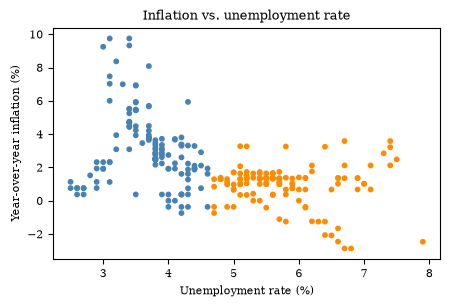

In [47]:
import numpy as np

# Colors for low- and high-unemployment periods
colors = np.array(['steelblue', 'darkorange'])

plt.figure(figsize=(5, 3))

# Specify colors based on the UNRATE_HIGH indicator
plt.scatter(
    df['UNRATE'], df['Inflation'], color=colors[df['UNRATE_HIGH'].astype(int)], s=10
)
plt.xlabel('Unemployment rate (%)')
plt.ylabel('Year-over-year inflation (%)')
_ = plt.title('Inflation vs. unemployment rate')

#### Part 5 — Calendar-year average inflation

For each calendar year, we average the available monthly year-over-year inflation
rates. There is no average for 1948 because all 12 monthly inflation values are
missing.

In [48]:
# Create groups based on calendar year
groups = df.resample('YE')

# Average monthly year-over-year inflation within each calendar year
infl_avg = groups['Inflation'].mean()

# Sort in descending order and print the three years with highest average inflation
infl_avg.sort_values(ascending=False).head(3)

DATE
1951-12-31    7.987456
1969-12-31    5.432647
1968-12-31    4.241319
Name: Inflation, dtype: float64

Alternatively, you can perform these actions in one line:

In [49]:
df.resample('YE')['Inflation'].mean().sort_values(ascending=False).head(3)

DATE
1951-12-31    7.987456
1969-12-31    5.432647
1968-12-31    4.241319
Name: Inflation, dtype: float64

To plot the calendar-year averages of monthly year-over-year inflation rates, we
use pandas's plotting functions:

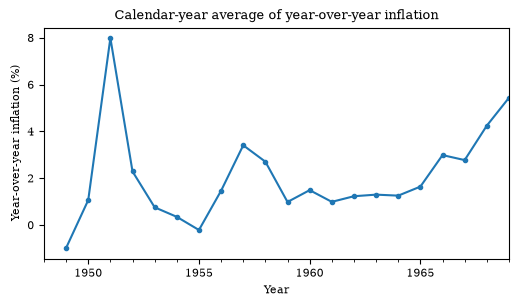

In [50]:
_ = infl_avg.plot.line(
    xlabel='Year',
    ylabel='Year-over-year inflation (%)',
    title='Calendar-year average of year-over-year inflation',
    figsize=(6, 3),
    marker='o',
    ms=3,
)

<span style="display: none;">SolutionEnd</span>

***
# Exercise 5: From ship arrivals to seasonal traffic

In this exercise, you're asked to aggregate individual ship arrivals to compare
vessel categories and seasonal traffic patterns. For this, we're using data from
Kystverket on reported arrivals at Bergen harbor for the complete calendar years
2013–2025. Each row represents one arrival, including repeat visits by the same
ship.

The file `kystverket/bergen_arrivals.csv.gz` contains four columns:

- `arrival`: Reported arrival time in Bergen local time.
- `vessel_type`: Detailed vessel type.
- `vessel_category`: Broad vessel category, such as passenger ships or
  cargo ships.
- `gross_tonnage`: Gross tonnage (GT), a measure of vessel size based on
  enclosed volume.

See the [data description](../../data/kystverket/README.md) for details.
Note that the extension `.csv.gz` indicates that the file is compressed in order to reduce the file size.

Run the supplied loading cell, then complete these tasks:

1.  Display the first five rows and report the total number of arrivals.

2.  Count arrivals by `vessel_category` and calculate each category's percentage
    of all arrivals. Display the results in descending order of arrival counts
    and create a horizontal bar chart of the counts.

    *Hint:* Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the arrival counts.

    *Hint:* You can use either `plt.barh()` or `DataFrame.plot.barh()` to create the bar chart.

3.  Compute the mean `gross_tonnage` for each `vessel_category`. Display all
    categories in descending order of mean gross tonnage and create a horizontal
    bar chart of these means.

4.  Count arrivals in each month separately for `Passenger ships` and
    `Cargo ships`. Store the results in a DataFrame named `df_monthly`, with one
    column per category, and plot both monthly series in one line chart.

    *Hint:* There are several ways to implement this. One way is to compute the monthly counts for each category separately and then combine the results into a single DataFrame.

5.  Use `groupby()` to calculate average monthly arrivals for each calendar
    month, from January through December. Create two seasonal bar charts, one
    per category, with a shared vertical scale. Describe the contrast in one
    sentence.

    *Hint:* Group `df_monthly` by `df_monthly.index.month`. Replace the resulting index with the supplied `month_names`. 
    
    *Hint:* Use
    `plot.bar(subplots=True, layout=(1, 2), sharey=True)` for the two panels when plotting with the pandas plotting API.

In [51]:
import pandas as pd

# Relative path to the data directory
DATA_PATH = '../../data'
# Path to the compressed Bergen arrivals CSV file
file = f'{DATA_PATH}/kystverket/bergen_arrivals.csv.gz'

# Parse arrival times and prepare a chronological date index
df_arrivals = pd.read_csv(file, parse_dates=['arrival'], index_col='arrival')

# Sort arrivals in chronological order
df_arrivals = df_arrivals.sort_index()

# Labels for the seasonal bar charts
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec',
]

## Solution

#### Part 1 — Inspecting arrivals

In [52]:
print(f'Number of arrivals: {len(df_arrivals):,}')
df_arrivals.head()

Number of arrivals: 45,620


,vessel_type,vessel_category,gross_tonnage
arrival,,,
2013-01-01 03:00:00,Platform Supply Ship,Offshore and special-purpose vessels,3350.0
2013-01-01 12:10:00,Diving Support Vessel,Offshore and special-purpose vessels,7502.0
2013-01-01 19:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 01:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 03:45:00,Tug,Offshore and special-purpose vessels,370.0


#### Part 2 — Arrivals by vessel category

In [53]:
# Count arrival records in each category
counts = df_arrivals.groupby('vessel_category').size()
counts = counts.sort_values(ascending=False)

# Express each category's count as a percentage of all arrivals
shares = 100 * counts / counts.sum()

# Tabulate both counts and shares using a DataFrame
df_categories = pd.DataFrame({'arrivals': counts, 'share_percent': shares})
df_categories.round(1)

,arrivals,share_percent
vessel_category,,
Cargo ships,17799,39.0
Offshore and special-purpose vessels,12953,28.4
Passenger ships,10141,22.2
Tankers,3488,7.6
Fishing vessels,995,2.2
Unknown,194,0.4
Recreational vessels,50,0.1


We can plot this data as a bar chart using either Matplotlib or pandas's plotting functions. The following code uses Matplotlib:

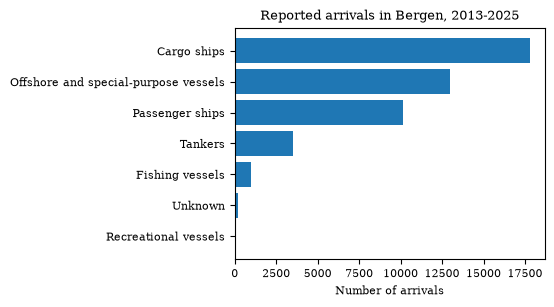

In [54]:
import matplotlib.pyplot as plt

# Reverse order to have largest category on top
counts_ascending = counts.sort_values()

plt.barh(counts_ascending.index, counts_ascending)
plt.title('Reported arrivals in Bergen, 2013-2025')
_ = plt.xlabel('Number of arrivals')

Alternatively, we can use the pandas plotting API. This works by calling the plotting functions directly on the (sorted) `Series` object: 

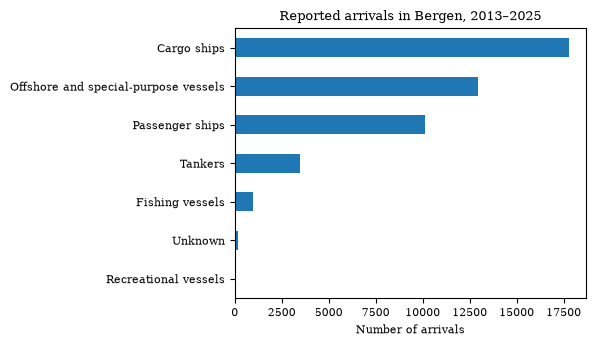

In [55]:
# Create bar chart using pandas's plotting functions
counts_ascending.plot.barh(
    figsize=(6, 3.5),
    xlabel='Number of arrivals',
    ylabel='',
    title='Reported arrivals in Bergen, 2013–2025',
)
plt.tight_layout()

#### Part 3 — Mean gross tonnage

We average gross tonnage across arrival records within each vessel category.
Ships with more visits receive more weight in these averages.

In [56]:
# Average vessel size within each category, ignoring missing values
avg_tonnage = df_arrivals.groupby('vessel_category')['gross_tonnage'].mean()

# Sort in descending order
avg_tonnage = avg_tonnage.sort_values(ascending=False)
avg_tonnage.round(1)

vessel_category
Passenger ships                         36060.1
Cargo ships                              5156.7
Offshore and special-purpose vessels     4862.8
Tankers                                  2171.4
Fishing vessels                          1636.2
Unknown                                  1120.0
Recreational vessels                       95.3
Name: gross_tonnage, dtype: float64

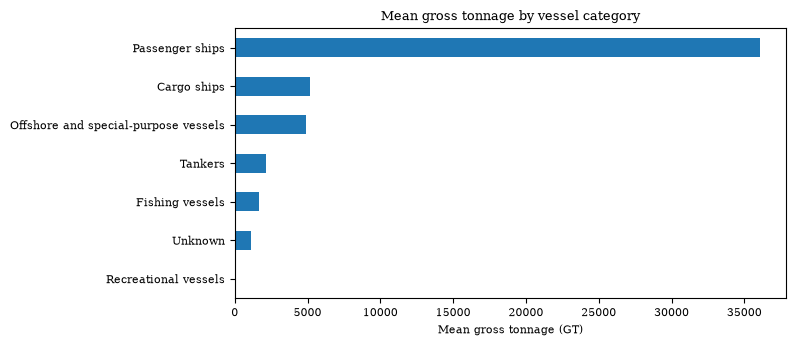

In [57]:
# Ascending order places the largest mean at the top of the chart
avg_tonnage.sort_values().plot.barh(
    figsize=(8, 3.5),
    xlabel='Mean gross tonnage (GT)',
    ylabel='',
    title='Mean gross tonnage by vessel category',
)
plt.tight_layout()

#### Part 4 — Monthly arrival counts

There are several ways to solve this problem.
We can use more advanced pandas functionality to combine `groupby()` and
`resample()` to compute the monthly counts for all categories in one step. For
readability, the following code splits the chained operations across multiple
lines:

In [58]:
# Categories to keep for this part
categories = ['Passenger ships', 'Cargo ships']

# Compute monthly aggregates for each vessel category
df_monthly = df_arrivals.groupby('vessel_category').resample('ME').size()

# Move the 'vessel_category' level to the columns
df_monthly = df_monthly.unstack(level='vessel_category')

# Select only the two categories of interest
df_monthly = df_monthly[categories]

df_monthly.head()

vessel_category,Passenger ships,Cargo ships
arrival,,
2013-01-31,10.0,137.0
2013-02-28,16.0,132.0
2013-03-31,18.0,149.0
2013-04-30,20.0,156.0
2013-05-31,65.0,177.0


However, this can also be computed in a single chained operation as follows,
omitting any intermediate results:

In [59]:
# Compute statistics in a single chained operation
df_monthly = (
    df_arrivals.groupby('vessel_category')
    .resample('ME')
    .size()
    .unstack(level='vessel_category')[categories]
)

df_monthly.head()

vessel_category,Passenger ships,Cargo ships
arrival,,
2013-01-31,10.0,137.0
2013-02-28,16.0,132.0
2013-03-31,18.0,149.0
2013-04-30,20.0,156.0
2013-05-31,65.0,177.0


Another way to compute these statistics is to loop over the desired categories,
compute the monthly series of arrivals for that category, and store it as a
column in a `DataFrame`:

In [60]:
df_monthly = pd.DataFrame()

for category in categories:
    # Select individual arrivals before counting records in each month
    df_category = df_arrivals[df_arrivals['vessel_category'] == category]
    df_monthly[category] = df_category.resample('ME').size()

df_monthly.head()

,Passenger ships,Cargo ships
arrival,,
2013-01-31,10,137
2013-02-28,16,132
2013-03-31,18,149
2013-04-30,20,156
2013-05-31,65,177


Finally, we plot this data again using either Matplotlib or pandas's plotting functions. The following code uses Matplotlib:

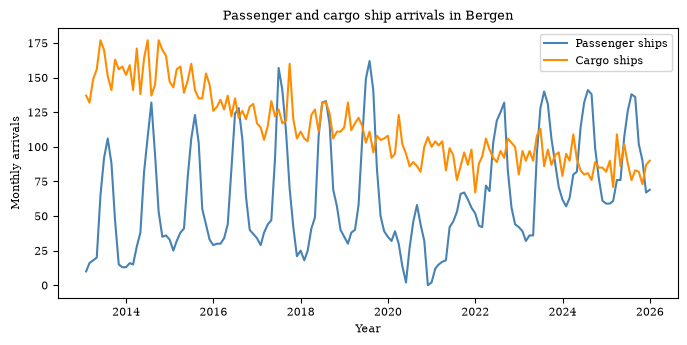

In [61]:
plt.figure(figsize=(8, 3.5))
plt.plot(
    df_monthly.index,
    df_monthly['Passenger ships'],
    label='Passenger ships',
    c='steelblue',
    lw=1.5,
)
plt.plot(
    df_monthly.index,
    df_monthly['Cargo ships'],
    label='Cargo ships',
    c='darkorange',
    lw=1.5,
)
plt.xlabel('Year')
plt.ylabel('Monthly arrivals')
plt.title('Passenger and cargo ship arrivals in Bergen')
_ = plt.legend()

The next cell shows how this can be done using the pandas plotting API:

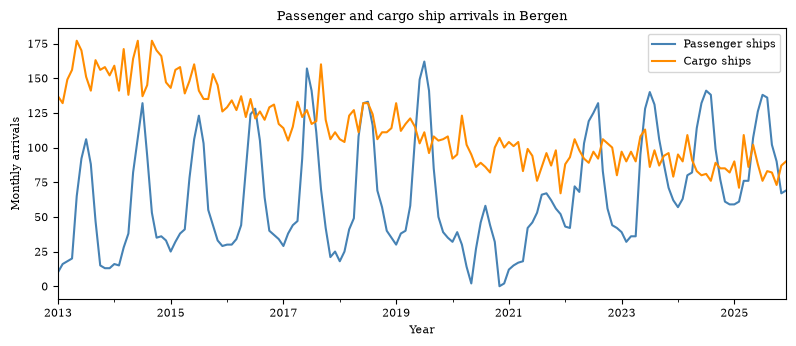

In [62]:
df_monthly.plot.line(
    figsize=(8, 3.5),
    xlabel='Year',
    ylabel='Monthly arrivals',
    title='Passenger and cargo ship arrivals in Bergen',
    color=['steelblue', 'darkorange'],
    linewidth=1.5,
)
plt.tight_layout()

#### Part 5 — Seasonal arrival patterns

We average the 13 monthly counts (one for each year) for each calendar month. This replaces the
month-by-month loop used in Workshop 3 with a grouped aggregation.

In [63]:
# Average January counts across years, then February counts, and so on
df_seasonal = df_monthly.groupby(df_monthly.index.month).mean()
df_seasonal.index = month_names
df_seasonal.round(1)

,Passenger ships,Cargo ships
Jan,30.8,114.3
Feb,34.3,109.5
Mar,42.6,123.7
Apr,45.5,115.5
May,82.9,118.3
Jun,111.2,119.5
Jul,120.6,108.8
Aug,109.2,108.2
Sep,72.6,116.2
Oct,52.9,114.3


We create the plot using the Matplotlib function as follows:

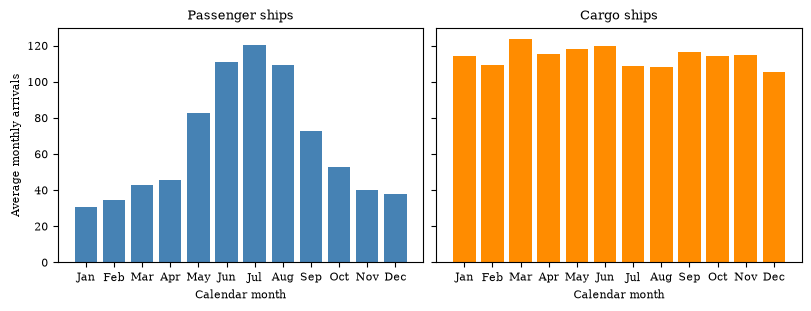

In [64]:
fig, axes = plt.subplots(
    1, 2, figsize=(8, 3), sharey=True, sharex=True, layout='constrained'
)
axes[0].bar(df_seasonal.index, df_seasonal['Passenger ships'], color='steelblue')
axes[0].set_title('Passenger ships')
axes[0].set_ylabel('Average monthly arrivals')
axes[0].set_xlabel('Calendar month')
axes[1].bar(df_seasonal.index, df_seasonal['Cargo ships'], color='darkorange')
axes[1].set_title('Cargo ships')
_ = axes[1].set_xlabel('Calendar month')

We can also create the plot using the pandas plotting API:

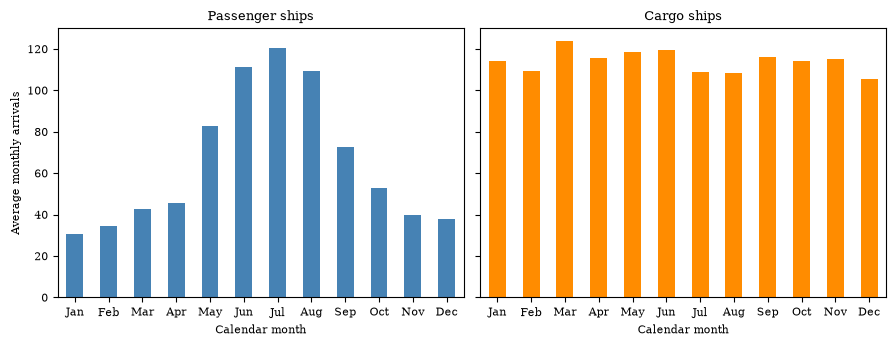

In [65]:
_ = df_seasonal.plot.bar(
    subplots=True,
    layout=(1, 2),
    sharey=True,
    figsize=(9, 3.5),
    legend=False,
    title=['Passenger ships', 'Cargo ships'],
    xlabel='Calendar month',
    ylabel='Average monthly arrivals',
    color=['steelblue', 'darkorange'],
    rot=0,
)
plt.tight_layout()

Passenger ship arrivals peak strongly in summer, while cargo ship arrivals are
much more evenly distributed across the year.

<span style="display: none;">SolutionEnd</span>